# LaLiga 2025/26 player archetypes — starter notebook

<a href="https://colab.research.google.com/github/sejaldua/laliga-player-roles/blob/main/notebooks/laliga_archetypes_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook loads everything you need to **cluster LaLiga outfield players into archetypes**. It shows how to:

1. get the data (it's cloned automatically, nothing to upload)
2. load the **one table you'll use most** (`model_features.csv`)
3. look up what any column means
4. pick feature families (season totals, style ratios, heatmap location)
5. map our homework's must-have stats to the columns that exist
6. work with heatmaps (summary, zones, raw points, plotting, custom grids)
7. a **bare-bones clustering skeleton** to start from (the real modelling is your job!)
8. per-90 stats, for ranking players *within* an archetype at the end

**Colab:** `Runtime → Run all`. Everything used here (pandas, numpy, scipy, scikit-learn, matplotlib) is pre-installed.

**Data:** SofaScore, LaLiga 2025/26 league matches only. Outfield players with ≥ 900 league minutes. Players who played for more than one club during the season are excluded so heatmaps aren't mixed.

## 1. Get the data

In [1]:
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/sejaldua/laliga-player-roles.git"
REPO_DIR = Path("laliga-player-roles")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
else:
    print("Repo already here, using existing copy (delete the folder to re-clone)")

DATA_DIR = REPO_DIR / "data" / "laliga_2025-26"
sorted(p.name for p in DATA_DIR.glob("*.csv"))

['data_dictionary.csv',
 'heatmap_points.csv',
 'heatmap_summary.csv',
 'heatmap_zones.csv',
 'model_features.csv',
 'player_positions.csv',
 'player_season_clubs.csv',
 'player_season_eligibility.csv',
 'player_season_per90.csv',
 'player_season_stats.csv',
 'player_transfers.csv',
 'players.csv',
 'seasons.csv',
 'teams.csv']

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)


def load(name, **kwargs):
    """Read one of the dataset's CSVs by short name, e.g. load("players")."""
    return pd.read_csv(DATA_DIR / f"{name}.csv", **kwargs)

### How the files fit together

Every file shares the key **`player_id`**; files with a `team_id` join to `teams.csv`. You usually only need the first one.

| File | One row per | Use it for |
|---|---|---|
| **`model_features.csv`** | eligible player | **Start here.** Everything below, already joined, for the 299 eligible players |
| `data_dictionary.csv` | table × column | What a column means, its unit, its SofaScore source |
| `player_season_eligibility.csv` | player in the pool (426) | Who's in/out and why (minutes, goalkeeper, mid-season mover) |
| `players.csv` / `player_positions.csv` | player / player × position | Bio, foot, height, every detailed position |
| `player_season_stats.csv` | player | Season **totals** + derived stats, for *all* 426 pool players |
| `player_season_per90.csv` | player | Per-90 versions, for ranking within an archetype later |
| `heatmap_summary.csv` | player | Average position, width, share of time per third |
| `heatmap_zones.csv` | player × pitch zone | Share of heatmap in each zone of a 6×5 grid (long format) |
| `heatmap_points.csv` | player × point | Raw SofaScore heatmap points (~420k rows), for plotting or custom grids |
| `player_season_clubs.csv`, `player_transfers.csv` | player × club spell / transfer | How mid-season movers were detected |
| `teams.csv`, `seasons.csv` | team / season | Possession % (used for PAdj stats), build settings |

## 2. The main table: `model_features.csv`

In [3]:
df = load("model_features").copy()
print(df.shape)
df[["player_name", "team_name", "primary_position_detailed", "minutes", "npxg", "xa",
    "padj_tackles_interceptions", "mean_x", "mean_y"]].sort_values("minutes", ascending=False).head()

(299, 162)


,player_name,team_name,primary_position_detailed,minutes,npxg,xa,padj_tackles_interceptions,mean_x,mean_y
49,Leandro Cabrera,Espanyol,DC,3330,2.7759,1.620120,53.7654,37.5601,66.0145
50,Martin Valjent,Mallorca,DC,3309,0.8101,0.329379,67.9245,33.1065,43.9050
166,Luis Milla,Getafe,MC,3273,1.2203,6.319770,85.1120,53.6972,46.5006
167,Mauro Arambarri,Getafe,MC,3255,4.7911,0.904205,75.0988,53.3010,62.2099
51,Nahuel Tenaglia,Deportivo Alavés,DR,3239,1.5876,0.460837,107.8010,35.5604,37.6386


### Position groups: use the *detailed* position, not SofaScore's broad one

SofaScore's broad `position` (`D`/`M`/`F`) files most wingers as midfielders. Our archetype homework splits players by role instead: **DEF = CB/LB/RB, MID = CDM/CM/CAM, ATT = LW/ST/RW**. So we build `role_group` from `primary_position_detailed`.

`ML`/`MR` (wide midfielders) are put with the attackers here, since they play as wingers. Change it if you disagree, but **write the decision down.**

In [4]:
ROLE_GROUP = {
    "DC": "DEF", "DL": "DEF", "DR": "DEF",
    "DM": "MID", "MC": "MID", "AM": "MID",
    "LW": "ATT", "RW": "ATT", "ST": "ATT",
    "ML": "ATT", "MR": "ATT",   # wide midfielders, effectively wingers (judgement call)
}
df["role_group"] = df["primary_position_detailed"].map(ROLE_GROUP)

print(pd.crosstab(df["primary_position_detailed"], df["position"], margins=True), "\n")
df["role_group"].value_counts()

position                     D   F    M  All
primary_position_detailed                   
AM                           0   0   18   18
DC                          59   0    2   61
DL                          27   0    1   28
DM                           0   0    1    1
DR                          31   0    1   32
LW                           0   5   14   19
MC                           0   0   67   67
ML                           0   1    5    6
MR                           0   1    8    9
RW                           0   2   13   15
ST                           0  40    3   43
All                        117  49  133  299 



role_group
DEF    121
ATT     92
MID     86
Name: count, dtype: int64

## 3. What does a column mean? The data dictionary

There are ~160 columns, so don't memorise them; look them up.

In [5]:
dd = load("data_dictionary")
dd_model = dd[dd["table"] == "model_features"].set_index("column")


def explain(*cols):
    """Unit, family and description for one or more model_features columns."""
    return dd_model.loc[list(cols), ["family", "unit", "description", "sofascore_key"]]


explain("npxg", "padj_tackles", "style_box_touch_share", "mean_y", "zone_x5_y2")

,family,unit,description,sofascore_key
column,,,,
npxg,derived,xG,Non-penalty xG = xg - pen_xg x penalties taken,NaN
padj_tackles,derived,count,Tackles x 50 / opponent possession % (team sea...,NaN
style_box_touch_share,derived,ratio,Opp-box touches / touches,NaN
mean_y,heatmap,0-100,Weighted mean y (lateral; ~0 = right touchline...,NaN
zone_x5_y2,heatmap,ratio,Share of heatmap points in zone x5_y2 (6x5 grid),NaN


In [6]:
# columns per family
dd_model.groupby("family").size().sort_values(ascending=False)

family
heatmap            43
derived            38
key/dimension      13
defending          13
passing            11
shooting            8
carrying            7
creation            6
duels               6
set_piece_flags     4
volume              4
physical            4
finishing           3
discipline          2
dtype: int64

## 4. Who's in the dataset, and why

`player_season_eligibility.csv` has one boolean per rule for all 426 players with ≥ 450 league minutes. `is_eligible` is the AND of all of them. To change a rule (e.g. a 600-minute cut-off), rebuild the eligible set from this table plus `player_season_stats.csv`. Don't edit `model_features`.

In [7]:
elig = load("player_season_eligibility")
flags = [c for c in elig.columns if c.startswith(("is_", "has_"))]
elig[flags].sum()

is_goalkeeper               29
is_under_min_minutes        78
is_multi_club_in_season     41
has_transfer_in_window      84
is_career_unavailable        0
has_no_season_stats          0
is_eligible                299
dtype: int64

In [8]:
# Who were the mid-season movers? (the João Cancelo rule: >1 club under 25/26 in the player's Career tab)
clubs = load("player_season_clubs")
players = load("players")

movers = elig.loc[elig["is_multi_club_in_season"] & ~elig["is_goalkeeper"], "player_id"]
(clubs[clubs["player_id"].isin(movers) & clubs["counts_as_club_spell"]]
 .groupby(["player_id", "team_name"], as_index=False)["minutes"].sum()
 .merge(players[["player_id", "player_name"]], on="player_id")
 .assign(spell=lambda d: d["team_name"] + " (" + d["minutes"].astype(str) + " min)")
 .groupby("player_name")["spell"].agg(" + ".join)
 .head(12))

player_name
Ademola Lookman       Atalanta (1240 min) + Atlético Madrid (1381 min)
Adrià Pedrosa                      Elche (1387 min) + Sevilla (13 min)
Alfon González                Sevilla (476 min) + Villarreal (334 min)
Batista Mendy                Sevilla (1646 min) + Trabzonspor (56 min)
Bryan Zaragoza               AS Roma (191 min) + Celta Vigo (1420 min)
Carlos Martín        Atlético Madrid (66 min) + Rayo Vallecano (531...
Carlos Vicente       Birmingham City (1066 min) + Deportivo Alavés ...
Claudio Echeverri    Bayer 04 Leverkusen (281 min) + Girona FC (618...
Clemens Riedel            Darmstadt 98 (189 min) + Espanyol (1492 min)
Conor Gallagher      Atlético Madrid (1062 min) + Tottenham Hotspur...
Etta Eyong                Levante UD (1462 min) + Villarreal (257 min)
Fer López              Celta Vigo (1431 min) + Wolverhampton (370 min)
Name: spell, dtype: str

In [9]:
# Example: the same dataset with a 600-minute threshold instead of 900, built by joining the tidy tables
MIN_MINUTES = 600
alt_ids = elig.loc[
    (elig["minutes"] >= MIN_MINUTES) & ~elig["is_goalkeeper"] & ~elig["is_multi_club_in_season"], "player_id"]
stats_all = load("player_season_stats")
alt = stats_all[stats_all["player_id"].isin(alt_ids)]
print(f"{len(alt)} players at >= {MIN_MINUTES} min (vs {len(df)} at 900)")

335 players at >= 600 min (vs 299 at 900)


## 5. Feature families

All of these live in `model_features`. Choosing which families go into the clustering is the most important modelling decision you'll make.

| Family | Columns | Notes |
|---|---|---|
| **Season totals** | `shots`, `npxg`, `tackles`, `crosses`, … | What we agreed to use for roles (not per-90). They grow with minutes, so check how much your clusters just track playing time (diagnostic in §8). |
| **Possession-adjusted** | `padj_*` | Tackles/interceptions/clearances scaled by the opponent's possession, so a Barça defender isn't penalised for his team always having the ball. Uses season-average possession. |
| **Rates** | `*_pct`, `npxg_per_shot` | Quality/efficiency (e.g. `aerial_win_pct`). Noisy when the denominator is small. |
| **Style ratios** | `style_*` | Share of a player's activity (per touch / per pass / share of defensive actions). Doesn't depend on minutes: describes *how* he plays, not how much. |
| **Heatmap location** | `mean_x`, `mean_y`, `std_*`, `share_*`, `zone_x?_y?` | *Where* he plays. Arguably the single most role-defining signal. |
| **Set-piece flags** | `sp_*`, `is_set_piece_taker` | **Do not cluster on these**, or you'll "discover" the corner-taker cluster. |
| **Physical** | `distance_km`, `sprints`, `top_speed_kmh` | Tracking coverage is incomplete; use with care. |

In [10]:
ID_COLS = ["league", "season_id", "player_id", "player_name", "team_id", "team_name", "position",
           "position_group", "primary_position_detailed", "role_group", "preferred_foot"]
fam = dd_model["family"]

FEATURES = {
    "totals": [c for c in fam.index if fam[c] not in ("derived", "heatmap", "key/dimension", "set_piece_flags",
                                                       "physical", "discipline", "volume")],
    "derived_totals": ["np_shots", "npxg", "np_goals", "npxg_plus_xa", "aerials_contested", "tackles_interceptions"],
    "padj": [c for c in df.columns if c.startswith("padj_")],
    "rates": [c for c in df.columns if c.endswith("_pct") or c == "npxg_per_shot"],
    "style": [c for c in df.columns if c.startswith("style_")],
    "heatmap_summary": ["mean_x", "mean_y", "std_x", "std_y", "mean_abs_width", "share_def_third",
                        "share_mid_third", "share_att_third", "share_wide", "share_central_lane", "share_opp_box"],
    "heatmap_zones": [c for c in df.columns if c.startswith("zone_x")],
    "DO_NOT_USE_set_pieces": [c for c in df.columns if c.startswith("sp_")] + ["is_set_piece_taker"],
}
{k: len(v) for k, v in FEATURES.items()}

{'totals': 54,
 'derived_totals': 6,
 'padj': 4,
 'rates': 10,
 'style': 17,
 'heatmap_summary': 11,
 'heatmap_zones': 30,
 'DO_NOT_USE_set_pieces': 5}

## 6. Homework must-have stats → dataset columns

Each must-have stat from the archetype homework (with its weight), mapped to the closest column. `status` is how good the match is:

- **exact**: same stat
- **close**: same idea, slightly different definition
- **proxy**: related signal standing in for an unavailable stat
- **missing**: SofaScore doesn't publish it (progressive carries/passes received, pressures, carries into the box are FBref/Opta-style metrics)

Missing stats' weight is spread over the remaining ones in `homework_matrix` below. Decide whether that's what you want.

In [11]:
# (homework stat, column or None, weight, status, archetype it mainly signals)
MUST_HAVE = {
    "DEF": [
        ("Progressive Passes",        "opp_half_passes_completed",    .11, "proxy",   "Progressive Defender"),
        ("Progressive Carries",       None,                           .10, "missing", "Progressive / Wide Attacking"),
        ("PAdj Tackles",              "padj_tackles",                 .09, "exact",   "Front-Foot Ball-Winner"),
        ("PAdj Interceptions",        "padj_interceptions",           .09, "exact",   "Cover Defender"),
        ("Clearances",                "clearances",                   .08, "exact",   "Box Defender"),
        ("Ball Recoveries",           "ball_recoveries",              .07, "exact",   "Cover / Front-Foot"),
        ("Aerial Duels Won",          "aerials_won",                  .07, "exact",   "Box Defender"),
        ("Blocks",                    "blocks",                       .06, "exact",   "Box Defender"),
        ("Aerial Duel Win %",         "aerial_win_pct",               .05, "exact",   "Box Defender"),
        ("Long Passes Completed",     "long_balls_completed",         .05, "close",   "Progressive Defender"),
        ("Crosses into Penalty Area", "crosses",                      .05, "close",   "Wide Attacking Defender"),
        ("Pressures",                 "possession_won_att_third",     .05, "proxy",   "Front-Foot Ball-Winner"),
        ("Touches in Attacking Third","share_att_third",              .05, "proxy",   "Wide Attacking Defender"),
        ("xA",                        "xa",                           .04, "exact",   "Wide Attacking Defender"),
        ("Passes into Final Third",   "final_third_passes_completed", .04, "close",   "Progressive Defender"),
    ],
    "MID": [
        ("Progressive passes",        "opp_half_passes_completed",    .11, "proxy",   "Deep Playmaker"),
        ("npxG",                      "npxg",                         .08, "exact",   "Goal-Threat Midfielder"),
        ("xA",                        "xa",                           .08, "exact",   "Advanced Creator"),
        ("Progressive carries",       None,                           .08, "missing", "Box-to-Box / Advanced Creator"),
        ("Pressures",                 "possession_won_att_third",     .08, "proxy",   "Ball-Winner / Presser"),
        ("Passes attempted",          "passes",                       .07, "exact",   "Deep Playmaker"),
        ("PAdj Tackles",              "padj_tackles",                 .07, "exact",   "Ball-Winner / Presser"),
        ("PAdj Interceptions",        "padj_interceptions",           .07, "exact",   "Anchor"),
        ("Shot-creating actions",     "shot_assists",                 .06, "close",   "Advanced Creator"),
        ("Passes into final third",   "final_third_passes_completed", .06, "close",   "Deep Playmaker"),
        ("Ball Recoveries",           "ball_recoveries",              .06, "exact",   "Ball-Winner / Box-to-Box"),
        ("Touches in att. pen area",  "touches_opp_box",              .05, "exact",   "Goal-Threat / Box-to-Box"),
        ("Touches in defensive third","share_def_third",              .05, "proxy",   "Anchor"),
        ("Successful take-ons",       "take_ons_won",                 .04, "exact",   "Advanced Creator"),
        ("Blocks",                    "blocks",                       .04, "exact",   "Anchor"),
    ],
    "ATT": [
        ("npxG",                      "npxg",                         .12, "exact",   "Finisher"),
        ("xA",                        "xa",                           .09, "exact",   "Creator & Wide Crosser"),
        ("Attacking-third pressures", "possession_won_att_third",     .09, "proxy",   "Pressing Attacker"),
        ("Aerial duels won",          "aerials_won",                  .08, "exact",   "Target Forward"),
        ("Touches in att. pen area",  "touches_opp_box",              .08, "exact",   "Finisher vs Creator"),
        ("Shots",                     "np_shots",                     .06, "exact",   "Finisher"),
        ("npxG per shot",             "npxg_per_shot",                .06, "exact",   "Finisher"),
        ("Crosses into penalty area", "crosses",                      .06, "close",   "Wide Crosser"),
        ("Take-ons attempted",        "take_ons",                     .06, "exact",   "Dribbler"),
        ("Progressive passes received", None,                         .06, "missing", "Finisher"),
        ("Key Passes",                "key_passes",                   .05, "exact",   "Creator"),
        ("Passes attempted",          "passes",                       .04, "exact",   "Creator & Target Forward"),
        ("Take-on Success %",         "take_on_success_pct",          .04, "exact",   "Dribbler"),
        ("Progressive carries",       None,                           .04, "missing", "Dribbler"),
        ("Carries into penalty area", None,                           .04, "missing", "Dribbler"),
        ("PAdj Tackles & Interceptions", "padj_tackles_interceptions",.03, "exact",   "Pressing Attacker"),
    ],
}

coverage = pd.DataFrame(
    [(g, *row) for g, rows in MUST_HAVE.items() for row in rows],
    columns=["group", "stat", "column", "weight", "status", "archetype"])
coverage.groupby(["group", "status"])["weight"].sum().unstack(fill_value=0).round(2)

status,close,exact,missing,proxy
group,,,,
ATT,0.06,0.71,0.14,0.09
DEF,0.14,0.55,0.10,0.21
MID,0.12,0.56,0.08,0.24


In [12]:
def homework_matrix(frame, group):
    """Players of one role group x their must-have columns, plus the matching weights
    (missing stats dropped, weights re-normalised to sum to 1)."""
    rows = [(col, w) for _, col, w, status, _ in MUST_HAVE[group] if col is not None]
    cols = list(dict.fromkeys(c for c, _ in rows))                    # de-dupe, keep order
    weights = pd.Series({c: sum(w for cc, w in rows if cc == c) for c in cols})
    sub = frame[frame["role_group"] == group].set_index("player_name")
    return sub[cols], weights / weights.sum()


X_def, w_def = homework_matrix(df, "DEF")
print(X_def.shape)
w_def.round(3)

(121, 14)


opp_half_passes_completed       0.122
padj_tackles                    0.100
padj_interceptions              0.100
clearances                      0.089
ball_recoveries                 0.078
aerials_won                     0.078
blocks                          0.067
aerial_win_pct                  0.056
long_balls_completed            0.056
crosses                         0.056
possession_won_att_third        0.056
share_att_third                 0.056
xa                              0.044
final_third_passes_completed    0.044
dtype: float64

## 7. Heatmaps

Three levels of detail, from cheapest to richest:

1. **`heatmap_summary`-style columns** (already in `model_features`): ~11 numbers per player
2. **zones** (already in `model_features` as `zone_x{i}_y{j}`): share of the player's heatmap in each cell of a **6 (length) × 5 (width) grid**
3. **raw points** (`heatmap_points.csv`): for plotting, or to build your own grid

**Coordinates** (0–100 on both axes):

- **x** runs from your own goal line (0) to the opponent's goal line (100). Every player is shown attacking left → right.
- **y = 0 is the RIGHT touchline and y = 100 the LEFT** (checked against known left- and right-backs).
- Zone indices follow the same layout: `zone_x0` is your own end and `zone_x5` the opponent's; `zone_y0` is the right flank and `zone_y4` the left flank.

In [13]:
# Sanity check of the y-axis: left-backs should have high mean_y, right-backs low
df.groupby("primary_position_detailed")[["mean_x", "mean_y", "mean_abs_width", "share_att_third"]].mean().round(1)

,mean_x,mean_y,mean_abs_width,share_att_third
primary_position_detailed,,,,
AM,56.8,51.6,24.7,0.4
DC,35.0,50.7,20.2,0.1
DL,46.3,81.5,33.8,0.2
DM,45.2,46.4,20.0,0.1
DR,44.4,20.7,32.6,0.2
LW,61.6,64.2,30.0,0.5
MC,49.7,49.9,22.3,0.2
ML,56.8,64.1,29.7,0.4
MR,56.2,27.1,32.5,0.4


In [14]:
# Zones are stored LONG in heatmap_zones.csv; model_features has them already pivoted WIDE.
# Getting from long to wide yourself:
zones_long = load("heatmap_zones")
zones_wide = zones_long.pivot(index="player_id", columns=["zone_x", "zone_y"], values="share")
zones_wide.iloc[:3, :6]

zone_x            0                                                 1
zone_y            0         1         2         3         4         0
player_id                                                            
17651      0.001152  0.009217  0.001152  0.006912  0.014977  0.026498
19356      0.003215  0.001072  0.002144  0.001072  0.002144  0.025723
21555      0.056586  0.066790  0.025046  0.000000  0.000000  0.158627

In [15]:
# Raw points: ~420k rows. Load only the columns you need, with small dtypes (about 6x less memory).
points = load("heatmap_points", usecols=["player_id", "x", "y", "count"],
              dtype={"player_id": "int32", "x": "int8", "y": "int8", "count": "int16"})
print(f"{len(points):,} points, {points.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Keep only eligible players (and index by player for fast per-player lookups)
points = points[points["player_id"].isin(df["player_id"])].set_index("player_id").sort_index()

422,884 points, 3.4 MB


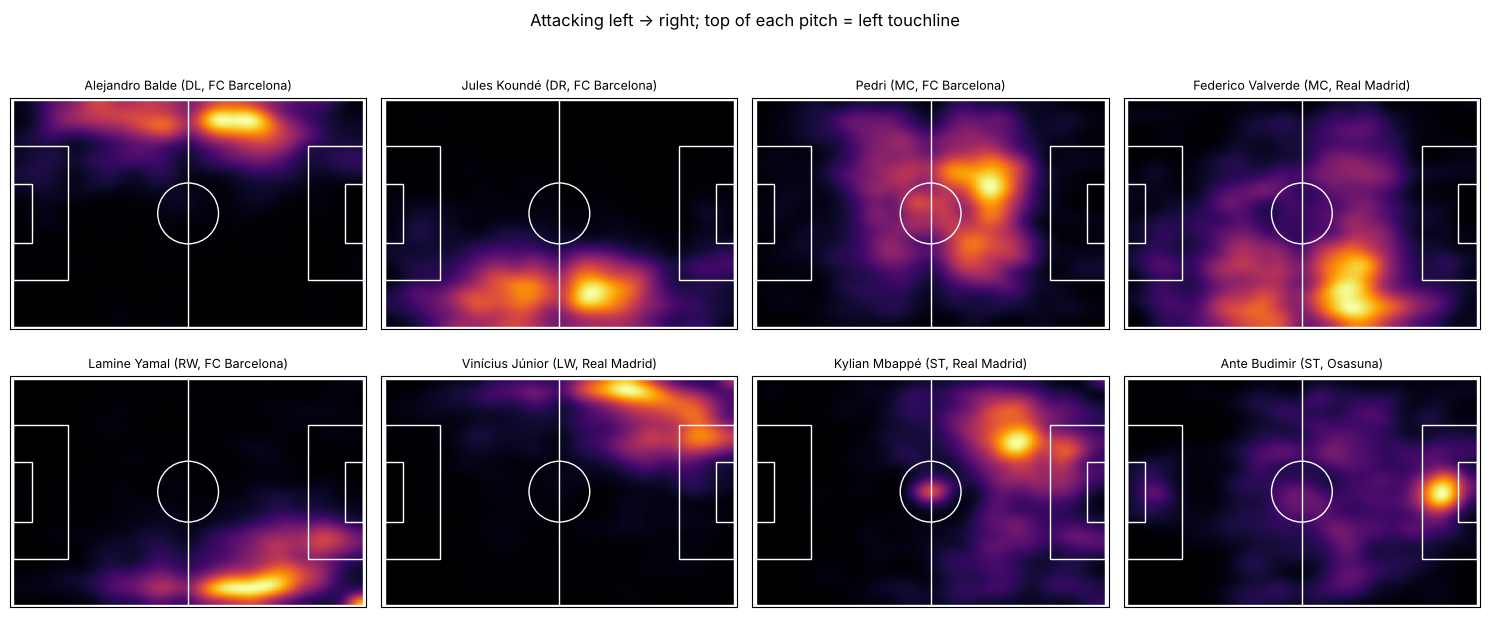

In [16]:
from matplotlib.patches import Rectangle, Ellipse
from scipy.ndimage import gaussian_filter


def draw_pitch(ax):
    """Pitch lines on SofaScore's 0-100 x 0-100 grid (attacking left -> right)."""
    kw = dict(fill=False, lw=1, color="white")
    ax.add_patch(Rectangle((0, 0), 100, 100, **kw))
    ax.plot([50, 50], [0, 100], color="white", lw=1)
    ax.add_patch(Ellipse((50, 50), 17.4, 26.9, **kw))
    for x0 in (0, 100 - 15.7):                               # penalty boxes
        ax.add_patch(Rectangle((x0, 20.4), 15.7, 59.2, **kw))
    for x0 in (0, 100 - 5.2):                                # six-yard boxes
        ax.add_patch(Rectangle((x0, 36.8), 5.2, 26.4, **kw))
    ax.set_xlim(-1, 101); ax.set_ylim(-1, 101); ax.set_xticks([]); ax.set_yticks([])


def player_heatmap(player_name, ax=None, sigma=3.5):
    """SofaScore-style smoothed season heatmap for one player."""
    row = df.loc[df["player_name"] == player_name].iloc[0]
    pts = points.loc[[row["player_id"]]]
    H, _, _ = np.histogram2d(pts["x"], pts["y"], bins=100, range=[[0, 100], [0, 100]], weights=pts["count"])
    H = gaussian_filter(H, sigma)
    ax = ax or plt.gca()
    ax.imshow(H.T, origin="lower", extent=[0, 100, 0, 100], cmap="inferno", aspect=68 / 105)
    draw_pitch(ax)
    ax.set_title(f"{player_name} ({row['primary_position_detailed']}, {row['team_name']})", fontsize=9)
    return ax


examples = ["Alejandro Balde", "Jules Koundé", "Pedri", "Federico Valverde",
            "Lamine Yamal", "Vinícius Júnior", "Kylian Mbappé", "Ante Budimir"]
examples = [p for p in examples if p in set(df["player_name"])]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for name, ax in zip(examples, axes.flat):
    player_heatmap(name, ax)
plt.suptitle("Attacking left → right; top of each pitch = left touchline", y=1.0)
plt.tight_layout()

In [17]:
def zone_grid(points, nx=12, ny=8):
    """Your own zone grid from the raw points: returns players x (nx*ny) shares, rows sum to 1.
    Fully vectorised: no per-player Python loop."""
    p = points.reset_index()
    zx = np.minimum(p["x"].astype(int) * nx // 100, nx - 1)
    zy = np.minimum(p["y"].astype(int) * ny // 100, ny - 1)
    grid = (p.assign(zone=[f"z{a:02d}_{b:02d}" for a, b in zip(zx, zy)])
              .pivot_table(index="player_id", columns="zone", values="count", aggfunc="sum", fill_value=0))
    return grid.div(grid.sum(axis=1), axis=0)


grid_12x8 = zone_grid(points, 12, 8)
print(grid_12x8.shape)
grid_12x8.iloc[:3, :8].round(3)

(299, 96)


zone,z00_00,z00_01,z00_02,z00_03,z00_04,z00_05,z00_06,z00_07
player_id,,,,,,,,
17651,0.000,0.000,0.001,0.000,0.001,0.001,0.005,0.002
19356,0.000,0.002,0.000,0.000,0.000,0.000,0.000,0.000
21555,0.007,0.012,0.027,0.002,0.005,0.000,0.000,0.000


## 8. A bare-bones clustering skeleton

This is the scaffolding, **not** the answer. It runs one role group through a minimal pipeline so you can see the shape of the problem:

1. pick features
2. impute
3. scale
4. weight
5. reduce
6. cluster
7. inspect

Every choice here (feature set, weights, k, algorithm) is something your project should test and justify.

In [18]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

GROUP = "MID"   # try "DEF" and "ATT" too

# Features: homework must-haves (weighted) + where the player stands (heatmap summary)
X_hw, w_hw = homework_matrix(df, GROUP)
loc_cols = [c for c in FEATURES["heatmap_summary"] if c not in X_hw.columns]   # avoid double-counting
X_loc = df[df["role_group"] == GROUP].set_index("player_name")[loc_cols]
X = pd.concat([X_hw, X_loc], axis=1)
weights = pd.concat([w_hw * 0.7, pd.Series(0.3 / X_loc.shape[1], index=X_loc.columns)])  # 70% stats / 30% location

Z = SimpleImputer(strategy="median").fit_transform(X)
Z = StandardScaler().fit_transform(Z) * np.sqrt(weights.values)   # sqrt: weights apply to squared distances

for k in range(3, 9):
    labels = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(Z)
    print(k, round(silhouette_score(Z, labels), 3))

3 0.221
4 0.224
5 0.179
6 0.182
7 0.182
8 0.166


In [19]:
K = 6            # e.g. one per homework archetype for MID; justify your own choice
km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(Z)
out = X.assign(cluster=km.labels_, minutes=df.set_index("player_name").loc[X.index, "minutes"])

# Most typical players per cluster = closest to the centroid
dist = np.linalg.norm(Z - km.cluster_centers_[km.labels_], axis=1)
out["dist_to_centroid"] = dist
for c, g in out.sort_values("dist_to_centroid").groupby("cluster"):
    print(f"cluster {c} ({len(g)}): " + ", ".join(g.index[:6]))

cluster 0 (7): Jude Bellingham, Dani Olmo, Fermín López, Oihan Sancet, Mauro Arambarri, Azzedine Ounahi
cluster 1 (17): Pepelu, Jon Gorrotxategi, Marc Roca, Eduardo Camavinga, Óscar Valentín, Ilaix Moriba
cluster 2 (9): Koke, Mikel Jauregizar, Federico Valverde, Aleix Febas, Iñigo Ruiz de Galarreta, Frenkie de Jong
cluster 3 (14): Pablo Marín, Ramón Terrats, Jon Guridi, Martim Neto, Peque Fernández, André Almeida
cluster 4 (23): Alberto Reina, Pablo Torre, Pedro Díaz, Jon Ander Olasagasti, Denis Suárez, Isi Palazón
cluster 5 (16): Oriol Rey, Alejandro Rego Mora, Sergi Altimira, Iker Muñoz, Miguel Román, Beñat Turrientes


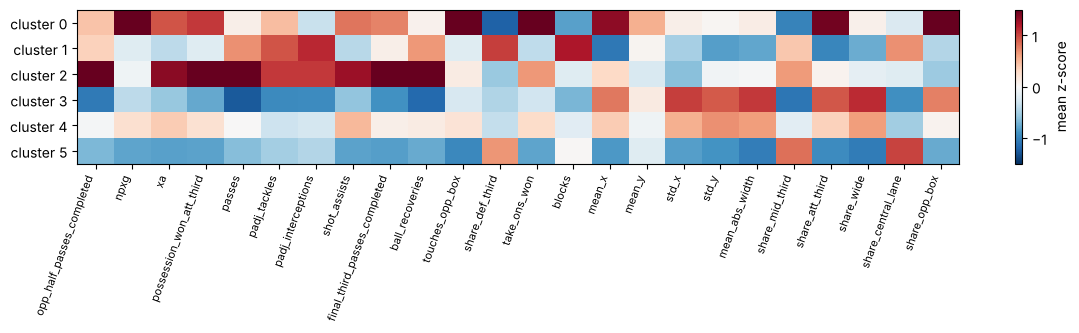

In [20]:
# What makes each cluster different? Mean z-score of each feature per cluster
profile = pd.DataFrame(StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X)),
                       index=X.index, columns=X.columns).groupby(km.labels_).mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(profile.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(profile.columns)), profile.columns, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(K), [f"cluster {i}" for i in range(K)])
plt.colorbar(im, label="mean z-score"); plt.tight_layout()

variance explained by PC1, PC2: [0.36 0.28]
corr(PC1, minutes) = 0.75


Text(0.5, 1.0, 'MID clusters (PCA view)')

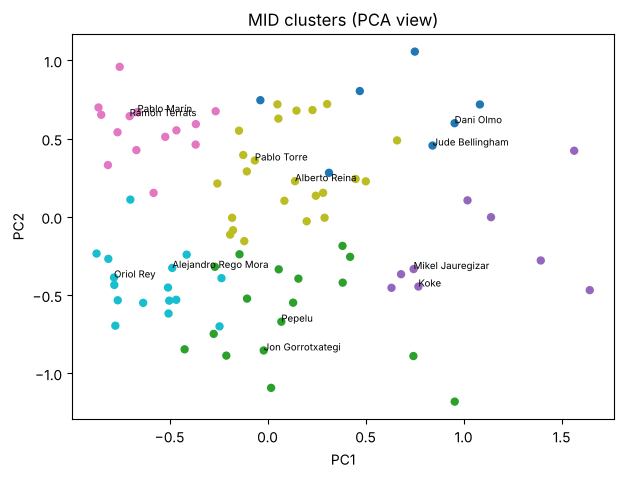

In [21]:
# Diagnostic: are the clusters just "how much he played"? We cluster on season TOTALS, which grow with minutes.
pc = PCA(n_components=2).fit(Z)
pcs = pc.transform(Z)
print("variance explained by PC1, PC2:", pc.explained_variance_ratio_.round(2))
print("corr(PC1, minutes) =", round(np.corrcoef(pcs[:, 0], out["minutes"])[0, 1], 2))

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=km.labels_, cmap="tab10", s=25)
for name in out.sort_values("dist_to_centroid").groupby("cluster").head(2).index:
    i = out.index.get_loc(name)
    ax.annotate(name, pcs[i], fontsize=7)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"{GROUP} clusters (PCA view)")
# If |corr| is high, a big part of what separates players is volume. Compare against the
# minutes-independent families (FEATURES["style"], heatmap zones) before deciding.

## 9. Per-90: ranking players *within* an archetype

We cluster on season totals and style, which captures **what** a player does. To ask **who does it best**, join the per-90 table on `player_id` and rank inside each cluster.

In [22]:
p90 = load("player_season_per90")
ranked = (out[["cluster"]].reset_index()
          .merge(df[["player_name", "player_id"]], on="player_name")
          .merge(p90, on="player_id"))
ranked.sort_values(["cluster", "npxg_plus_xa_p90"], ascending=[True, False]) \
      .groupby("cluster").head(3)[["cluster", "player_name", "minutes", "npxg_plus_xa_p90",
                                   "padj_tackles_interceptions_p90"]].round(2)

,cluster,player_name,minutes,npxg_plus_xa_p90,padj_tackles_interceptions_p90
35,0,Dani Olmo,2077,0.58,3.26
45,0,Fermín López,1797,0.57,4.41
37,0,Arda Güler,2026,0.52,3.01
17,1,Santi Comesaña,2413,0.29,2.45
30,1,Pape Gueye,2143,0.25,2.80
11,1,Aurélien Tchouaméni,2622,0.19,4.86
5,2,Pablo Fornals,2865,0.31,2.30
33,2,Pedri,2107,0.30,5.06
53,2,Frenkie de Jong,1637,0.27,5.46
81,3,Unai Gómez,949,0.30,1.29


## 10. Caveats to keep in mind

- **Season totals scale with minutes.** That's intended: we're describing roles, not per-90 quality. But check the PC1–minutes correlation above and compare against the minutes-independent families (`style_*`, heatmap zones).
- **Missing stats.** Progressive passes/carries, pressures, carries into the box and progressive passes received don't exist in SofaScore. The proxies in §6 are stand-ins, not replacements.
- **PAdj** uses each team's **season-average** possession, not match-by-match.
- **Heatmaps** cover LaLiga matches only. They show *where the player was involved*, not where he stood off the ball.
- **Eligibility:** ≥ 900 minutes, no goalkeepers, no mid-season movers (any second club, including abroad). `seasons.csv` records the exact settings this build used.